In [1]:
import pandas as pd
import os
import librosa
import librosa.display
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pickle
import joblib
from sklearn.model_selection import train_test_split
import hub
import numpy as np
from sklearn.model_selection import train_test_split
from pathlib import Path
import random
import shutil
import time

In [2]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import v2
from torch.utils.data import Dataset

In [3]:
# ds = hub.load("hub://activeloop/spoken_mnist")

In [4]:
# # check out the first spectrogram, it's label, and who spoke it!
# import matplotlib.pyplot as plt
# plt.imshow(ds.spectrograms[0].numpy())
# plt.title(f"{ds.speakers[0].data()} spoke {ds.labels[0].numpy()}")
# plt.show()

In [5]:
#get the fsdd recordings
dataset_dir = Path("free-spoken-digit-dataset/recordings/")

In [6]:
#get the .wav file paths
wav_paths = list(dataset_dir.glob("**/*.wav"))

In [7]:
#we're going to create a dataframe that includes all the pertinent information from the audio recordings, so we can eventually turn them into spectrograms and run them through a CNN
data_list = []
#iterate through the .wav files
for path in wav_paths:
    # load() returns the audio time series (y) as a numpy array and the sampling rate (sr)
    #Raw audio is a 1D time-series signal representing air pressure or displacement variations over time. We get a value between -1.0 and 1.0, with the frequency being informed by the sampling rate
    #A sampling rate is the number of times per second an analog signal is measured and converted into digital data (Hz)
    y, sr = librosa.load(path, sr=None)  

    #now we'll create a dictionary of pertinant information of the .wav file, and appending it to the data_list, which will inform our dataframe  
    data_list.append({
        "file_name": path.name,
        "file_path": str(path),
        "audio_array": y,
        "sample_rate": sr,
        "duration_sec": librosa.get_duration(y=y, sr=sr)
    })

In [8]:
#data_list can now be used to create a pandas dataframe (audio_df). 
audio_df = pd.DataFrame(data_list)
#let's look at the audio time series
print(audio_df.audio_array.head())

0    [-0.045440674, -0.02935791, -0.018493652, 0.00...
1    [0.0010986328, 0.0005493164, 0.0019226074, 0.0...
2    [-0.005340576, -0.015533447, 0.00894165, 0.007...
3    [0.0031433105, 0.004211426, 0.0059814453, 0.00...
4    [0.0020446777, 0.0027770996, 0.0031738281, 0.0...
Name: audio_array, dtype: object


In [9]:
#the recordings are not all the same length. Bummer. This makes analyzing them as a group difficult.
#we can deal with this by adding a buffer of silence (zeros) at the end of the recording. 
#we decide how much buffer to add based on the longest clip
max_length = max(len(clip) for clip in audio_df.audio_array)

padded_clips = []
for clip in audio_df.audio_array:
    pad_amount = max_length - len(clip)
    padded = np.pad(clip, (0, pad_amount), mode='constant', constant_values=0)
    padded_clips.append(padded)

In [10]:
#we can add this to the audio dataframe. we now have the y of the original recording as well as the padded version.
audio_df['uniform_audio'] = padded_clips

print(audio_df.head())

         file_name                                          file_path  \
0   0_george_0.wav  free-spoken-digit-dataset\recordings\0_george_...   
1   0_george_1.wav  free-spoken-digit-dataset\recordings\0_george_...   
2  0_george_10.wav  free-spoken-digit-dataset\recordings\0_george_...   
3  0_george_11.wav  free-spoken-digit-dataset\recordings\0_george_...   
4  0_george_12.wav  free-spoken-digit-dataset\recordings\0_george_...   

                                         audio_array  sample_rate  \
0  [-0.045440674, -0.02935791, -0.018493652, 0.00...         8000   
1  [0.0010986328, 0.0005493164, 0.0019226074, 0.0...         8000   
2  [-0.005340576, -0.015533447, 0.00894165, 0.007...         8000   
3  [0.0031433105, 0.004211426, 0.0059814453, 0.00...         8000   
4  [0.0020446777, 0.0027770996, 0.0031738281, 0.0...         8000   

   duration_sec                                      uniform_audio  
0      0.298000  [-0.045440674, -0.02935791, -0.018493652, 0.00...  
1      0

In [11]:
#to create the labels, we can get the speaker names from the file names. 
speaker_name = []

for name in audio_df.file_name:
    parts = name.rsplit(".", 1)[0].split("_")
    digit = parts[0]
    speaker = parts[1]
    speaker_name.append(speaker)

In [12]:
all_speakers = list(set(speaker_name))

In [13]:
#another column to the dataframe
audio_df['speaker_name'] = speaker_name

In [14]:
import numpy as np
import librosa.display, os
import matplotlib.pyplot as plt
%matplotlib inline

#in order to train a model on these recordings, we need to convert them into images. we can convert them into spectrograms
def create_spectrogram(y, sr, image_file):
    fig = plt.figure()
    ax = fig.add_subplot(1, 1, 1)
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)

    ms = librosa.feature.melspectrogram(y=y, sr=sr)
    log_ms = librosa.power_to_db(ms, ref=np.max)
    librosa.display.specshow(log_ms, sr=sr)

    fig.savefig(image_file)
    plt.close(fig)
    
def create_pngs_from_wavs(audio_data_y, audio_data_sr, audio_data_file_name, output_path):
    for i, file in enumerate(audio_data_file_name):
        output_file = os.path.join(output_path, file.replace('.wav', '.png'))
        create_spectrogram(audio_data_y[i], audio_data_sr[i], output_file)

In [15]:
#convert all audio files into spectrograms
create_pngs_from_wavs(audio_df.uniform_audio, audio_df.sample_rate, audio_df.file_name, "spectrograms")

In [16]:
"""#now that we have spectrograms for all of our audio files, we can divide them into training/testing
input_dir = 'spectrograms/all'
train_dir = 'spectrograms/training'
test_dir = 'spectrograms/testing'

#make the full directory, make sure they both indeed exist
os.makedirs(train_dir, exist_ok=True)
os.makedirs(test_dir, exist_ok=True)

# Get all png files and only the .png files from the input directory, then shuffle them
images = [f for f in os.listdir(input_dir) if f.endswith('.png')]
random.shuffle(images)

# 80/20 split index for training/test
split_index = int(len(images) * 0.8)
train_images = images[:split_index]
test_images = images[split_index:]

# Copy files to respective directories
for img in train_images:
    shutil.copy(os.path.join(input_dir, img), os.path.join(train_dir, img))

for img in test_images:
    shutil.copy(os.path.join(input_dir, img), os.path.join(test_dir, img))"""

"#now that we have spectrograms for all of our audio files, we can divide them into training/testing\ninput_dir = 'spectrograms/all'\ntrain_dir = 'spectrograms/training'\ntest_dir = 'spectrograms/testing'\n\n#make the full directory, make sure they both indeed exist\nos.makedirs(train_dir, exist_ok=True)\nos.makedirs(test_dir, exist_ok=True)\n\n# Get all png files and only the .png files from the input directory, then shuffle them\nimages = [f for f in os.listdir(input_dir) if f.endswith('.png')]\nrandom.shuffle(images)\n\n# 80/20 split index for training/test\nsplit_index = int(len(images) * 0.8)\ntrain_images = images[:split_index]\ntest_images = images[split_index:]\n\n# Copy files to respective directories\nfor img in train_images:\n    shutil.copy(os.path.join(input_dir, img), os.path.join(train_dir, img))\n\nfor img in test_images:\n    shutil.copy(os.path.join(input_dir, img), os.path.join(test_dir, img))"

In [17]:
"""import os
import pandas as pd
from torchvision.io import decode_image

class CustomImageDataset(Dataset):
    def __init__(self, annotations_file, img_dir, transform=None, target_transform=None):
        self.img_labels = pd.read_csv(annotations_file)
        self.img_dir = img_dir
        self.transform = transform
        self.target_transform = target_transform

    def __len__(self):
        return len(self.img_labels)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_labels.iloc[idx, 0])
        image = decode_image(img_path)
        label = self.img_labels.iloc[idx, 1]
        if self.transform:
            image = self.transform(image)
        if self.target_transform:
            label = self.target_transform(label)
        return image, label"""

'import os\nimport pandas as pd\nfrom torchvision.io import decode_image\n\nclass CustomImageDataset(Dataset):\n    def __init__(self, annotations_file, img_dir, transform=None, target_transform=None):\n        self.img_labels = pd.read_csv(annotations_file)\n        self.img_dir = img_dir\n        self.transform = transform\n        self.target_transform = target_transform\n\n    def __len__(self):\n        return len(self.img_labels)\n\n    def __getitem__(self, idx):\n        img_path = os.path.join(self.img_dir, self.img_labels.iloc[idx, 0])\n        image = decode_image(img_path)\n        label = self.img_labels.iloc[idx, 1]\n        if self.transform:\n            image = self.transform(image)\n        if self.target_transform:\n            label = self.target_transform(label)\n        return image, label'

In [18]:
"""#we'll make an ordered list of the image labels for the training set
labels_list_training = []

for file in train_images:
    parts = file.rsplit(".", 1)[0].split("_")
    digit = parts[0]
    speaker = parts[1]

    labels_list_training.append({
        "file_name": file,
        "speaker_name": speaker
    }
                    )

training_labels_df = pd.DataFrame(labels_list_training)
print(training_labels_df)"""

'#we\'ll make an ordered list of the image labels for the training set\nlabels_list_training = []\n\nfor file in train_images:\n    parts = file.rsplit(".", 1)[0].split("_")\n    digit = parts[0]\n    speaker = parts[1]\n\n    labels_list_training.append({\n        "file_name": file,\n        "speaker_name": speaker\n    }\n                    )\n\ntraining_labels_df = pd.DataFrame(labels_list_training)\nprint(training_labels_df)'

In [19]:
"""#and the same for the testing set
labels_list_testing = []

for file in test_images:
    parts = file.rsplit(".", 1)[0].split("_")
    digit = parts[0]
    speaker = parts[1]

    labels_list_testing.append({
        "file_name": file,
        "speaker_name": speaker
    }
                    )

testing_labels_df = pd.DataFrame(labels_list_testing)
print(testing_labels_df)"""

'#and the same for the testing set\nlabels_list_testing = []\n\nfor file in test_images:\n    parts = file.rsplit(".", 1)[0].split("_")\n    digit = parts[0]\n    speaker = parts[1]\n\n    labels_list_testing.append({\n        "file_name": file,\n        "speaker_name": speaker\n    }\n                    )\n\ntesting_labels_df = pd.DataFrame(labels_list_testing)\nprint(testing_labels_df)'

In [20]:
input_dir = 'spectrograms'
# Get all png files and only the .png files from the input directory, then shuffle them
images = [f for f in os.listdir(input_dir) if f.endswith('.png')]
random.shuffle(images)

labels = []

for file in images:
    parts = file.rsplit(".", 1)[0].split("_")
    digit = parts[0]
    speaker = parts[1]

    labels.append({
        "file_name": file,
        "speaker_name": speaker
    }
                    )

labels_df = pd.DataFrame(labels)
print(labels_df)

             file_name speaker_name
0        5_theo_33.png         theo
1     8_jackson_18.png      jackson
2         9_theo_0.png         theo
3      3_george_31.png       george
4      9_george_43.png       george
...                ...          ...
2995  4_nicolas_15.png      nicolas
2996   0_george_13.png       george
2997     6_theo_30.png         theo
2998     8_lucas_5.png        lucas
2999  2_jackson_46.png      jackson

[3000 rows x 2 columns]


In [21]:
classes = sorted(set(all_speakers))                  # your 6 category names
class_to_idx = {c: i for i, c in enumerate(classes)}
print(class_to_idx)                                # keep this, you'll want it later

{'george': 0, 'jackson': 1, 'lucas': 2, 'nicolas': 3, 'theo': 4, 'yweweler': 5}


In [22]:
#the CustomImageDataset class recieves the image directory and corresponding labels defined in the cells above
import os
from torchvision.io import decode_image, ImageReadMode

class CustomImageDataset(Dataset):
    def __init__(self, annotations_file, img_dir, transform=None, target_transform=None):
        self.img_labels = annotations_file
        self.img_dir = img_dir
        self.transform = transform
        self.target_transform = target_transform

    def __len__(self): #the len(dataset) returns the amount of labels, to correspond with the amount of files in the set
        return len(self.img_labels)

    def __getitem__(self, idx): #getting an index of the dataset data[idx] returns the image, transformed and target transformed as defines, and the corresponding label
        img_name = self.img_labels.iloc[idx, 0]
        img_path = os.path.join(self.img_dir, img_name)
        image = decode_image(img_path, mode=ImageReadMode.RGB)
        label = self.img_labels.iloc[idx, 1]
        if self.transform:
            image = self.transform(image)
        if self.target_transform:
            label = self.target_transform(label)
        return image, label

In [23]:
from torchvision.transforms import v2
import torch

#transform = v2.ToDtype(torch.float32, scale=True)   # uint8 0-255 -> float32 0-1
transform = v2.Compose([
    v2.Resize((128, 160), antialias=True),
    v2.ToDtype(torch.float32, scale=True),
])


In [24]:
from sklearn.model_selection import train_test_split

labels = labels_df.iloc[:, 1]
train_df, test_df = train_test_split(
    labels_df, test_size=0.2, stratify=labels, random_state=0)

# sanity checks
print(set(train_df.iloc[:, 0]) & set(test_df.iloc[:, 0]))   # should be empty set()
print(train_df.iloc[:, 1].value_counts())
print(test_df.iloc[:, 1].value_counts())

"""train_set = CustomImageDataset(train_df.reset_index(drop=True), 'spectrograms/all',
                               transform=transform, target_transform=label_to_idx)
test_set  = CustomImageDataset(test_df.reset_index(drop=True),  'spectrograms/all',
                               transform=transform, target_transform=label_to_idx)"""

set()
speaker_name
yweweler    400
theo        400
nicolas     400
jackson     400
george      400
lucas       400
Name: count, dtype: int64
speaker_name
jackson     100
theo        100
nicolas     100
lucas       100
yweweler    100
george      100
Name: count, dtype: int64


"train_set = CustomImageDataset(train_df.reset_index(drop=True), 'spectrograms/all',\n                               transform=transform, target_transform=label_to_idx)\ntest_set  = CustomImageDataset(test_df.reset_index(drop=True),  'spectrograms/all',\n                               transform=transform, target_transform=label_to_idx)"

In [25]:
"""training_data = CustomImageDataset(
    annotations_file=training_labels_df,
    img_dir="spectrograms/training", transform = transform, target_transform=lambda lbl:class_to_idx[lbl]
)"""
train_set = CustomImageDataset(train_df.reset_index(drop=True), 'spectrograms',
                               transform=transform, target_transform=lambda lbl:class_to_idx[lbl])
test_set  = CustomImageDataset(test_df.reset_index(drop=True),  'spectrograms',
                               transform=transform, target_transform=lambda lbl:class_to_idx[lbl])

In [26]:
"""test_data = CustomImageDataset(
    annotations_file=testing_labels_df,
    img_dir="spectrograms/testing", transform = transform, target_transform=lambda lbl:class_to_idx[lbl]
)"""

'test_data = CustomImageDataset(\n    annotations_file=testing_labels_df,\n    img_dir="spectrograms/testing", transform = transform, target_transform=lambda lbl:class_to_idx[lbl]\n)'

In [27]:
from torch.utils.data import DataLoader

#prepare the datasets to go through the models
train_dataloader = DataLoader(
    train_set,
    batch_size=64, #group data into mini batches
    shuffle=True
)

test_dataloader = DataLoader(
    test_set,
    batch_size=64,
    shuffle=False
)

In [28]:
"""image, label = train_set[0]

print(image.shape) #channels, height, width
print(label)"""

'image, label = train_set[0]\n\nprint(image.shape) #channels, height, width\nprint(label)'

Feature batch shape: torch.Size([64, 3, 128, 160])
Labels: tensor([0, 2, 4, 4, 1, 5, 2, 5, 5, 0, 4, 5, 1, 2, 1, 3, 0, 1, 0, 2, 1, 3, 2, 0,
        5, 2, 0, 2, 4, 5, 1, 2, 3, 4, 3, 2, 5, 0, 0, 3, 4, 5, 0, 1, 1, 4, 4, 3,
        4, 1, 4, 5, 3, 1, 3, 2, 4, 2, 1, 2, 2, 0, 4, 1])


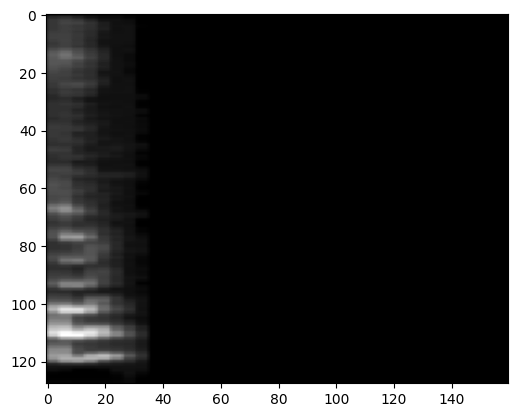

Label: 0


In [29]:
# Display image and label.
train_features, train_labels = next(iter(train_dataloader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels: {train_labels}")
img = train_features[0].squeeze()
label = train_labels[0]
plt.imshow(img[1], cmap="gray")
plt.show()
print(f"Label: {label}")

In [30]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cpu device


In [31]:
import torch
from torch import nn

class SpectrogramCNN(nn.Module):
    def __init__(self, in_channels=4, num_classes=6):
        super().__init__()

        def block(c_in, c_out):
            return nn.Sequential(
                nn.Conv2d(c_in, c_out, kernel_size=3, padding=1), #slides 3x3 stencils across the image
                nn.BatchNorm2d(c_out), #rescales maps from conv2d to stay in a sensible range
                nn.ReLU(), #negative values are zero. I only care of a pattern exists.
                nn.MaxPool2d(2),          # halves height and width, keeps largest value = strongest detections survive in smaller map
            )

        self.features = nn.Sequential(
            block(in_channels, 16),   # [16, 240, 320]
            block(16, 32),            # [32, 120, 160]
            block(32, 64),            # [64,  60,  80]
            block(64, 128),           # [128, 30,  40]
        )
        self.pool = nn.AdaptiveAvgPool2d((1, 1))   # [128, 1, 1], works for any input size, takes average of each of the 128 maps
        self.classifier = nn.Sequential(
            nn.Flatten(), #[128, 1, 1] turns into 128 numbers flat
            nn.Dropout(0.3), #randomly zeros some of these numbers for training, so we dont overrely on a single feature
            nn.Linear(128, num_classes),           # 6 outputs
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x)       # raw logits

model = SpectrogramCNN(in_channels=3, num_classes=6)
model.eval()
with torch.no_grad():
    print(model(torch.randn(2, 3, 128, 160)).shape)

torch.Size([2, 6])


In [32]:
def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, correct, n = 0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader: #x - images, a tensor shaped [32, 3, 224, 224], y - true labels, tensor or 32 class indices
            x, y = x.to(device), y.to(device) #both sent to device
            out = model(x)
            loss = criterion(out, y) #average loss per image in batch
            if train:
                optimizer.zero_grad() #clear the old gradients so they dont confuse the new calculations
                loss.backward() #compute new gradients (backpropagation)
                optimizer.step() #updates weights
            total_loss += loss.item() * x.size(0) #average losses * images in the batch = total losses
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

In [33]:
torch.manual_seed(0)
model = SpectrogramCNN(in_channels=3, num_classes=6).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

best_va = 0
for epoch in range(15):
    t0 = time.time()
    tl, ta = run_epoch(train_dataloader, train=True)
    vl, va = run_epoch(test_dataloader, train=False)
    print(f"Epoch {epoch+1}: train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.0f}s")
    if va > best_va:
        best_va = va
        torch.save(model.state_dict(), "baseline.pt")

Epoch 1: train loss 1.684 acc 0.327 | val loss 1.784 acc 0.168 | 73s
Epoch 2: train loss 1.423 acc 0.561 | val loss 1.367 acc 0.510 | 39s
Epoch 3: train loss 1.233 acc 0.647 | val loss 1.115 acc 0.768 | 36s
Epoch 4: train loss 1.081 acc 0.726 | val loss 1.009 acc 0.797 | 36s
Epoch 5: train loss 0.976 acc 0.767 | val loss 0.917 acc 0.773 | 36s
Epoch 6: train loss 0.899 acc 0.795 | val loss 0.832 acc 0.862 | 37s
Epoch 7: train loss 0.837 acc 0.820 | val loss 0.798 acc 0.828 | 44s
Epoch 8: train loss 0.776 acc 0.832 | val loss 0.732 acc 0.863 | 39s
Epoch 9: train loss 0.722 acc 0.862 | val loss 0.690 acc 0.872 | 40s
Epoch 10: train loss 0.677 acc 0.877 | val loss 0.647 acc 0.877 | 40s
Epoch 11: train loss 0.636 acc 0.895 | val loss 0.598 acc 0.908 | 45s
Epoch 12: train loss 0.593 acc 0.903 | val loss 0.578 acc 0.902 | 37s
Epoch 13: train loss 0.555 acc 0.915 | val loss 0.530 acc 0.928 | 36s
Epoch 14: train loss 0.521 acc 0.926 | val loss 0.482 acc 0.938 | 35s
Epoch 15: train loss 0.488 ac

can probably do a bit better

In [39]:
for epoch in range(15):
    t0 = time.time()
    tl, ta = run_epoch(train_dataloader, train=True)
    vl, va = run_epoch(test_dataloader, train=False)
    print(f"Epoch {epoch+16}: train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.0f}s")
    if va > best_va:
        best_va = va
        torch.save(model.state_dict(), "baseline.pt")

Epoch 16: train loss 0.457 acc 0.940 | val loss 0.423 acc 0.947 | 59s
Epoch 17: train loss 0.423 acc 0.943 | val loss 0.438 acc 0.922 | 56s
Epoch 18: train loss 0.399 acc 0.947 | val loss 0.388 acc 0.950 | 65s
Epoch 19: train loss 0.374 acc 0.955 | val loss 0.337 acc 0.965 | 59s
Epoch 20: train loss 0.348 acc 0.958 | val loss 0.324 acc 0.963 | 55s
Epoch 21: train loss 0.331 acc 0.958 | val loss 0.301 acc 0.967 | 55s
Epoch 22: train loss 0.304 acc 0.968 | val loss 0.308 acc 0.948 | 55s
Epoch 23: train loss 0.295 acc 0.968 | val loss 0.299 acc 0.962 | 55s
Epoch 24: train loss 0.279 acc 0.970 | val loss 0.273 acc 0.955 | 55s
Epoch 25: train loss 0.259 acc 0.973 | val loss 0.252 acc 0.970 | 55s
Epoch 26: train loss 0.245 acc 0.977 | val loss 0.236 acc 0.967 | 55s
Epoch 27: train loss 0.231 acc 0.978 | val loss 0.214 acc 0.980 | 55s
Epoch 28: train loss 0.218 acc 0.980 | val loss 0.207 acc 0.978 | 55s
Epoch 29: train loss 0.207 acc 0.984 | val loss 0.213 acc 0.965 | 55s
Epoch 30: train loss

Let's build a confusion matrix to see where the weak points are

              precision    recall  f1-score   support

      george       1.00      0.98      0.99       100
     jackson       1.00      1.00      1.00       100
       lucas       0.99      0.97      0.98       100
     nicolas       0.98      1.00      0.99       100
        theo       0.94      0.99      0.97       100
    yweweler       0.97      0.94      0.95       100

    accuracy                           0.98       600
   macro avg       0.98      0.98      0.98       600
weighted avg       0.98      0.98      0.98       600



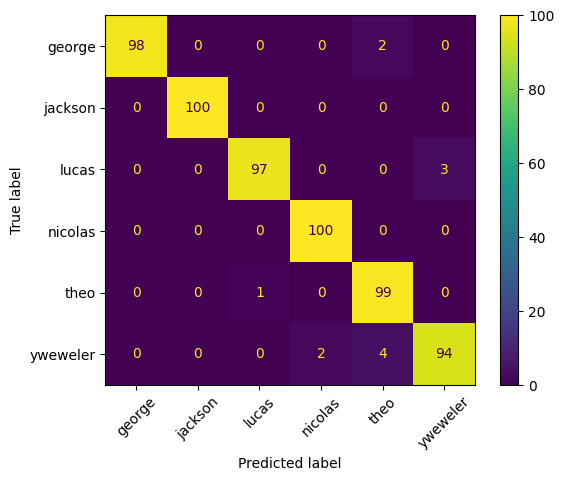

             file_name speaker_name
15     3_george_20.png       george
125     1_lucas_27.png        lucas
127     6_lucas_48.png        lucas
140  6_yweweler_21.png     yweweler
220   1_yweweler_8.png     yweweler
247  8_yweweler_33.png     yweweler
317    7_george_26.png       george
426   5_yweweler_6.png     yweweler
493      9_theo_16.png         theo
503     8_lucas_15.png        lucas
506  4_yweweler_39.png     yweweler
513  8_yweweler_27.png     yweweler


In [40]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import numpy as np

model.eval()
preds, truths = [], []
with torch.no_grad():
    for x, y in test_dataloader:
        preds.extend(model(x.to(device)).argmax(1).cpu().tolist())
        truths.extend(y.tolist())

print(classification_report(truths, preds, target_names=classes))
ConfusionMatrixDisplay(confusion_matrix(truths, preds), display_labels=classes).plot(xticks_rotation=45)
plt.show()

# which files were wrong?
wrong = test_df.reset_index(drop=True)[np.array(preds) != np.array(truths)]
print(wrong)

yweweler gets everyone confused

I'm going to run a few more experiments, just for fun. I dont imagine they're going to make a whole lot of difference, as the accuracy is already quite high, but this is good practice in any case. 

This set will have seed 36

In [44]:
torch.manual_seed(36)
model = SpectrogramCNN(in_channels=3, num_classes=6).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

history = []
best_va = 0
for epoch in range(30):
    t0 = time.time()
    tl, ta = run_epoch(train_dataloader, train=True)
    vl, va = run_epoch(test_dataloader, train=False)
    history.append((tl, ta, vl, va))
    print(f"Epoch {epoch+1}: train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.0f}s")
    if va > best_va:
        best_va = va
        torch.save(model.state_dict(), "baseline_experiment.pt")

last5 = history[-5:]
print(f"avg of last 5 epochs: val loss {sum(h[2] for h in last5)/5:.3f}, "
      f"val acc {sum(h[3] for h in last5)/5:.3f}")

Epoch 1: train loss 1.677 acc 0.340 | val loss 1.761 acc 0.167 | 55s
Epoch 2: train loss 1.423 acc 0.579 | val loss 1.313 acc 0.605 | 55s
Epoch 3: train loss 1.201 acc 0.699 | val loss 1.090 acc 0.785 | 55s
Epoch 4: train loss 1.058 acc 0.775 | val loss 0.989 acc 0.770 | 55s
Epoch 5: train loss 0.958 acc 0.802 | val loss 0.892 acc 0.817 | 55s
Epoch 6: train loss 0.869 acc 0.832 | val loss 0.822 acc 0.898 | 55s
Epoch 7: train loss 0.806 acc 0.851 | val loss 0.786 acc 0.867 | 55s
Epoch 8: train loss 0.757 acc 0.879 | val loss 0.724 acc 0.903 | 54s
Epoch 9: train loss 0.691 acc 0.888 | val loss 0.653 acc 0.907 | 55s
Epoch 10: train loss 0.640 acc 0.902 | val loss 0.614 acc 0.917 | 55s
Epoch 11: train loss 0.594 acc 0.908 | val loss 0.578 acc 0.917 | 52s
Epoch 12: train loss 0.561 acc 0.919 | val loss 0.510 acc 0.930 | 45s
Epoch 13: train loss 0.511 acc 0.928 | val loss 0.479 acc 0.935 | 45s
Epoch 14: train loss 0.482 acc 0.927 | val loss 0.450 acc 0.940 | 45s
Epoch 15: train loss 0.452 ac

Implementing a learning rate schedule could help with the wobbles

StepLR decays the learning rate by a factor of gamma every step_size epochs.

In [43]:
from torch.optim import lr_scheduler

torch.manual_seed(36)
model = SpectrogramCNN(in_channels=3, num_classes=6).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

scheduler = lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)

history = []

best_va = 0
for epoch in range(30):
    t0 = time.time()
    lr_used = optimizer.param_groups[0]["lr"] 
    tl, ta = run_epoch(train_dataloader, train=True)
    vl, va = run_epoch(test_dataloader, train=False)
    scheduler.step()
    history.append((tl, ta, vl, va))
    print(optimizer.param_groups[0]["lr"])
    print(f"Epoch {epoch+1}: train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.0f}s")
    if va > best_va:
        best_va = va
        torch.save(model.state_dict(), "steplr_experiment.pt")

last5 = history[-5:]
print(f"avg of last 5 epochs: val loss {sum(h[2] for h in last5)/5:.3f}, "
      f"val acc {sum(h[3] for h in last5)/5:.3f}")

0.0001
Epoch 1: train loss 1.677 acc 0.340 | val loss 1.761 acc 0.167 | 55s
0.0001
Epoch 2: train loss 1.423 acc 0.579 | val loss 1.313 acc 0.605 | 55s
0.0001
Epoch 3: train loss 1.201 acc 0.699 | val loss 1.090 acc 0.785 | 55s
0.0001
Epoch 4: train loss 1.058 acc 0.775 | val loss 0.989 acc 0.770 | 55s
0.0001
Epoch 5: train loss 0.958 acc 0.802 | val loss 0.892 acc 0.817 | 55s
0.0001
Epoch 6: train loss 0.869 acc 0.832 | val loss 0.822 acc 0.898 | 55s
0.0001
Epoch 7: train loss 0.806 acc 0.851 | val loss 0.786 acc 0.867 | 54s
0.0001
Epoch 8: train loss 0.757 acc 0.879 | val loss 0.724 acc 0.903 | 55s
0.0001
Epoch 9: train loss 0.691 acc 0.888 | val loss 0.653 acc 0.907 | 55s
5e-05
Epoch 10: train loss 0.640 acc 0.902 | val loss 0.614 acc 0.917 | 55s
5e-05
Epoch 11: train loss 0.598 acc 0.906 | val loss 0.564 acc 0.922 | 54s
5e-05
Epoch 12: train loss 0.583 acc 0.913 | val loss 0.551 acc 0.922 | 146s
5e-05
Epoch 13: train loss 0.553 acc 0.920 | val loss 0.523 acc 0.930 | 55s
5e-05
Epoch

Another learning rate option. Decays smoothly in small and stable steps

In [45]:
torch.manual_seed(36)
model = SpectrogramCNN(in_channels=3, num_classes=6).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)
history = []

best_va = 0
for epoch in range(30):
    t0 = time.time()
    lr_used = optimizer.param_groups[0]["lr"] 
    tl, ta = run_epoch(train_dataloader, train=True)
    vl, va = run_epoch(test_dataloader, train=False)
    scheduler.step()
    history.append((tl, ta, vl, va))
    print(optimizer.param_groups[0]["lr"])
    print(f"Epoch {epoch+1}: train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.0f}s")
    if va > best_va:
        best_va = va
        torch.save(model.state_dict(), "cosineannealinglr_experiment.pt")

last5 = history[-5:]
print(f"avg of last 5 epochs: val loss {sum(h[2] for h in last5)/5:.3f}, "
      f"val acc {sum(h[3] for h in last5)/5:.3f}")


9.972609476841367e-05
Epoch 1: train loss 1.677 acc 0.340 | val loss 1.761 acc 0.167 | 47s
9.890738003669029e-05
Epoch 2: train loss 1.423 acc 0.579 | val loss 1.316 acc 0.592 | 46s
9.755282581475769e-05
Epoch 3: train loss 1.203 acc 0.699 | val loss 1.091 acc 0.792 | 47s
9.567727288213003e-05
Epoch 4: train loss 1.060 acc 0.775 | val loss 0.988 acc 0.783 | 46s
9.330127018922194e-05
Epoch 5: train loss 0.963 acc 0.801 | val loss 0.898 acc 0.818 | 46s
9.045084971874738e-05
Epoch 6: train loss 0.877 acc 0.826 | val loss 0.832 acc 0.895 | 46s
8.715724127386972e-05
Epoch 7: train loss 0.818 acc 0.848 | val loss 0.794 acc 0.868 | 46s
8.345653031794292e-05
Epoch 8: train loss 0.773 acc 0.871 | val loss 0.734 acc 0.902 | 46s
7.938926261462366e-05
Epoch 9: train loss 0.713 acc 0.882 | val loss 0.678 acc 0.905 | 45s
7.500000000000001e-05
Epoch 10: train loss 0.670 acc 0.892 | val loss 0.640 acc 0.915 | 46s
7.033683215379003e-05
Epoch 11: train loss 0.629 acc 0.900 | val loss 0.591 acc 0.922 | 4

I think the models were still learning, Ill run them again with 50 epochs each

In [47]:
from torch.optim import lr_scheduler

torch.manual_seed(36)
model = SpectrogramCNN(in_channels=3, num_classes=6).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

scheduler = lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)

history = []

best_va = 0
for epoch in range(50):
    t0 = time.time()
    lr_used = optimizer.param_groups[0]["lr"] 
    tl, ta = run_epoch(train_dataloader, train=True)
    vl, va = run_epoch(test_dataloader, train=False)
    scheduler.step()
    history.append((tl, ta, vl, va))
    print(optimizer.param_groups[0]["lr"])
    print(f"Epoch {epoch+1}: train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.0f}s")
    if va > best_va:
        best_va = va
        torch.save(model.state_dict(), "steplr_experiment.pt")

last5 = history[-5:]
print(f"avg of last 5 epochs: val loss {sum(h[2] for h in last5)/5:.3f}, "
      f"val acc {sum(h[3] for h in last5)/5:.3f}")

0.0001
Epoch 1: train loss 1.677 acc 0.340 | val loss 1.761 acc 0.167 | 37s
0.0001
Epoch 2: train loss 1.423 acc 0.579 | val loss 1.313 acc 0.605 | 37s
0.0001
Epoch 3: train loss 1.201 acc 0.699 | val loss 1.090 acc 0.785 | 41s
0.0001
Epoch 4: train loss 1.058 acc 0.775 | val loss 0.989 acc 0.770 | 44s
0.0001
Epoch 5: train loss 0.958 acc 0.802 | val loss 0.892 acc 0.817 | 44s
0.0001
Epoch 6: train loss 0.869 acc 0.832 | val loss 0.822 acc 0.898 | 42s
0.0001
Epoch 7: train loss 0.806 acc 0.851 | val loss 0.786 acc 0.867 | 44s
0.0001
Epoch 8: train loss 0.757 acc 0.879 | val loss 0.724 acc 0.903 | 45s
0.0001
Epoch 9: train loss 0.691 acc 0.888 | val loss 0.653 acc 0.907 | 41s
5e-05
Epoch 10: train loss 0.640 acc 0.902 | val loss 0.614 acc 0.917 | 44s
5e-05
Epoch 11: train loss 0.598 acc 0.906 | val loss 0.564 acc 0.922 | 53s
5e-05
Epoch 12: train loss 0.583 acc 0.913 | val loss 0.551 acc 0.922 | 49s
5e-05
Epoch 13: train loss 0.553 acc 0.920 | val loss 0.523 acc 0.930 | 46s
5e-05
Epoch 

In [49]:
torch.manual_seed(36)
model = SpectrogramCNN(in_channels=3, num_classes=6).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)
history = []

best_va = 0
for epoch in range(50):
    t0 = time.time()
    lr_used = optimizer.param_groups[0]["lr"] 
    tl, ta = run_epoch(train_dataloader, train=True)
    vl, va = run_epoch(test_dataloader, train=False)
    scheduler.step()
    history.append((tl, ta, vl, va))
    print(optimizer.param_groups[0]["lr"])
    print(f"Epoch {epoch+1}: train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.0f}s")
    if va > best_va:
        best_va = va
        torch.save(model.state_dict(), "cosineannealinglr_experiment.pt")

last5 = history[-5:]
print(f"avg of last 5 epochs: val loss {sum(h[2] for h in last5)/5:.3f}, "
      f"val acc {sum(h[3] for h in last5)/5:.3f}")


9.972609476841367e-05
Epoch 1: train loss 1.677 acc 0.340 | val loss 1.761 acc 0.167 | 44s
9.890738003669029e-05
Epoch 2: train loss 1.423 acc 0.579 | val loss 1.316 acc 0.592 | 46s
9.755282581475769e-05
Epoch 3: train loss 1.203 acc 0.699 | val loss 1.091 acc 0.792 | 48s
9.567727288213003e-05
Epoch 4: train loss 1.060 acc 0.775 | val loss 0.988 acc 0.783 | 45s
9.330127018922194e-05
Epoch 5: train loss 0.963 acc 0.801 | val loss 0.898 acc 0.818 | 44s
9.045084971874738e-05
Epoch 6: train loss 0.877 acc 0.826 | val loss 0.832 acc 0.895 | 45s
8.715724127386972e-05
Epoch 7: train loss 0.818 acc 0.848 | val loss 0.794 acc 0.868 | 44s
8.345653031794292e-05
Epoch 8: train loss 0.773 acc 0.871 | val loss 0.734 acc 0.902 | 44s
7.938926261462366e-05
Epoch 9: train loss 0.713 acc 0.882 | val loss 0.678 acc 0.905 | 46s
7.500000000000001e-05
Epoch 10: train loss 0.670 acc 0.892 | val loss 0.640 acc 0.915 | 45s
7.033683215379003e-05
Epoch 11: train loss 0.629 acc 0.900 | val loss 0.591 acc 0.922 | 4

Another baseline run, but longer, so we have a good comparison

In [50]:
torch.manual_seed(36)
model = SpectrogramCNN(in_channels=3, num_classes=6).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

history = []
best_va = 0
for epoch in range(50):
    t0 = time.time()
    tl, ta = run_epoch(train_dataloader, train=True)
    vl, va = run_epoch(test_dataloader, train=False)
    history.append((tl, ta, vl, va))
    print(f"Epoch {epoch+1}: train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.0f}s")
    if va > best_va:
        best_va = va
        torch.save(model.state_dict(), "baseline_experiment_long.pt")

last5 = history[-5:]
print(f"avg of last 5 epochs: val loss {sum(h[2] for h in last5)/5:.3f}, "
      f"val acc {sum(h[3] for h in last5)/5:.3f}")

Epoch 1: train loss 1.677 acc 0.340 | val loss 1.761 acc 0.167 | 45s
Epoch 2: train loss 1.423 acc 0.579 | val loss 1.313 acc 0.605 | 45s
Epoch 3: train loss 1.201 acc 0.699 | val loss 1.090 acc 0.785 | 45s
Epoch 4: train loss 1.058 acc 0.775 | val loss 0.989 acc 0.770 | 45s
Epoch 5: train loss 0.958 acc 0.802 | val loss 0.892 acc 0.817 | 45s
Epoch 6: train loss 0.869 acc 0.832 | val loss 0.822 acc 0.898 | 45s
Epoch 7: train loss 0.806 acc 0.851 | val loss 0.786 acc 0.867 | 45s
Epoch 8: train loss 0.757 acc 0.879 | val loss 0.724 acc 0.903 | 46s
Epoch 9: train loss 0.691 acc 0.888 | val loss 0.653 acc 0.907 | 45s
Epoch 10: train loss 0.640 acc 0.902 | val loss 0.614 acc 0.917 | 45s
Epoch 11: train loss 0.594 acc 0.908 | val loss 0.578 acc 0.917 | 45s
Epoch 12: train loss 0.561 acc 0.919 | val loss 0.510 acc 0.930 | 44s
Epoch 13: train loss 0.511 acc 0.928 | val loss 0.479 acc 0.935 | 44s
Epoch 14: train loss 0.482 acc 0.927 | val loss 0.450 acc 0.940 | 44s
Epoch 15: train loss 0.452 ac

we can also change the rate of the Cosine learning rate, see how that affects it

In [51]:
torch.manual_seed(36)
model = SpectrogramCNN(in_channels=3, num_classes=6).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)

scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)
history = []

best_va = 0
for epoch in range(30):
    t0 = time.time()
    lr_used = optimizer.param_groups[0]["lr"] 
    tl, ta = run_epoch(train_dataloader, train=True)
    vl, va = run_epoch(test_dataloader, train=False)
    scheduler.step()
    history.append((tl, ta, vl, va))
    print(optimizer.param_groups[0]["lr"])
    print(f"Epoch {epoch+1}: train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.0f}s")
    if va > best_va:
        best_va = va
        torch.save(model.state_dict(), "cosineannealinglr_experiment_long.pt")

last5 = history[-5:]
print(f"avg of last 5 epochs: val loss {sum(h[2] for h in last5)/5:.3f}, "
      f"val acc {sum(h[3] for h in last5)/5:.3f}")


0.00029917828430524096
Epoch 1: train loss 1.493 acc 0.509 | val loss 1.840 acc 0.167 | 54s
0.0002967221401100708
Epoch 2: train loss 1.064 acc 0.740 | val loss 0.977 acc 0.753 | 53s
0.00029265847744427303
Epoch 3: train loss 0.843 acc 0.825 | val loss 0.789 acc 0.822 | 54s
0.0002870318186463901
Epoch 4: train loss 0.682 acc 0.884 | val loss 0.618 acc 0.908 | 55s
0.0002799038105676658
Epoch 5: train loss 0.564 acc 0.905 | val loss 0.518 acc 0.913 | 54s
0.0002713525491562421
Epoch 6: train loss 0.465 acc 0.934 | val loss 0.427 acc 0.935 | 56s
0.00026147172382160914
Epoch 7: train loss 0.408 acc 0.939 | val loss 0.404 acc 0.932 | 55s
0.00025036959095382875
Epoch 8: train loss 0.355 acc 0.953 | val loss 0.331 acc 0.953 | 55s
0.000238167787843871
Epoch 9: train loss 0.304 acc 0.959 | val loss 0.271 acc 0.963 | 55s
0.00022500000000000002
Epoch 10: train loss 0.264 acc 0.969 | val loss 0.237 acc 0.963 | 54s
0.0002110104964613701
Epoch 11: train loss 0.239 acc 0.968 | val loss 0.268 acc 0.952

In [56]:
torch.manual_seed(36)
model = SpectrogramCNN(in_channels=3, num_classes=6).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)

scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)
history = []

best_va = 0
for epoch in range(50):
    t0 = time.time()
    lr_used = optimizer.param_groups[0]["lr"] 
    tl, ta = run_epoch(train_dataloader, train=True)
    vl, va = run_epoch(test_dataloader, train=False)
    scheduler.step()
    history.append((tl, ta, vl, va))
    print(optimizer.param_groups[0]["lr"])
    print(f"Epoch {epoch+1}: train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.0f}s")
    if va > best_va:
        best_va = va
        torch.save(model.state_dict(), "cosineannealinglr_experiment_long.pt")

last5 = history[-5:]
print(f"avg of last 5 epochs: val loss {sum(h[2] for h in last5)/5:.3f}, "
      f"val acc {sum(h[3] for h in last5)/5:.3f}")


0.00029917828430524096
Epoch 1: train loss 1.518 acc 0.472 | val loss 1.508 acc 0.342 | 47s
0.0002967221401100708
Epoch 2: train loss 1.124 acc 0.704 | val loss 1.025 acc 0.693 | 47s
0.00029265847744427303
Epoch 3: train loss 0.879 acc 0.815 | val loss 0.793 acc 0.857 | 48s
0.0002870318186463901
Epoch 4: train loss 0.708 acc 0.880 | val loss 0.668 acc 0.877 | 48s
0.0002799038105676658
Epoch 5: train loss 0.600 acc 0.896 | val loss 0.592 acc 0.890 | 47s
0.0002713525491562421
Epoch 6: train loss 0.501 acc 0.922 | val loss 0.460 acc 0.927 | 48s
0.00026147172382160914
Epoch 7: train loss 0.434 acc 0.930 | val loss 0.428 acc 0.930 | 47s
0.00025036959095382875
Epoch 8: train loss 0.382 acc 0.945 | val loss 0.352 acc 0.937 | 47s
0.000238167787843871
Epoch 9: train loss 0.335 acc 0.953 | val loss 0.349 acc 0.925 | 48s
0.00022500000000000002
Epoch 10: train loss 0.292 acc 0.958 | val loss 0.285 acc 0.952 | 47s
0.0002110104964613701
Epoch 11: train loss 0.260 acc 0.968 | val loss 0.250 acc 0.963

30 epoch run, baseline - avg of last 5 epochs: val loss 0.208, val acc 0.970
50 epoch run, baseline - avg of last 5 epochs: val loss 0.097, val acc 0.987
50 epoch run, StepLR - avg of last 5 epochs: val loss 0.302, val acc 0.961 
50 epoch run, Cosine Annealing LR (1e-4) - avg of last 5 epochs: val loss 0.300, val acc 0.958 
50 epoch run, Cosine Annealing LR (3e-4) - avg of last 5 epochs: val loss 0.078, val acc 0.990
30 epoch run, Cosine Annealing LR (3e-4) - avg of last 5 epochs: val loss 0.095, val acc 0.988
30 epoch run, StepLR - avg of last 5 epochs: val loss 0.387, val acc 0.945
30 epoch run, Cosine Annealing LR (1e-4) - avg of last 5 epochs: val loss 0.352, val acc 0.952

Input standardization might help with the training.
we can standardize the pixel values around 0 +- 1. new_value = (value - mean)/std

In [52]:
base_transform = v2.Compose([
    v2.Resize((128, 160), antialias=True),
    v2.ToDtype(torch.float32, scale=True),
])

stats_set = CustomImageDataset(
    train_df.reset_index(drop=True), 'spectrograms',
    transform=base_transform,
    target_transform=lambda lbl: class_to_idx[lbl],
)
stats_loader = DataLoader(stats_set, batch_size=64, shuffle=False)

channel_sum = torch.zeros(3, dtype=torch.float64)
channel_sq_sum = torch.zeros(3, dtype=torch.float64)
pixel_count = 0

for x, _ in stats_loader:
    x = x.double()                                   # float64 avoids rounding drift
    channel_sum += x.sum(dim=(0, 2, 3))              # sum over batch, height, width
    channel_sq_sum += (x ** 2).sum(dim=(0, 2, 3))
    pixel_count += x.size(0) * x.size(2) * x.size(3)

train_mean = channel_sum / pixel_count
train_std = (channel_sq_sum / pixel_count - train_mean ** 2).sqrt()

train_mean = train_mean.tolist()
train_std = train_std.tolist()
print("mean:", train_mean)
print("std: ", train_std)

mean: [0.1530510477759857, 0.06061833549938279, 0.11586059252727635]
std:  [0.3050156735869008, 0.1420382100256634, 0.18363803347318333]


In [53]:
norm_transform = v2.Compose([
    v2.Resize((128, 160), antialias=True),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=train_mean, std=train_std),
])

train_set = CustomImageDataset(
    train_df.reset_index(drop=True), 'spectrograms',
    transform=norm_transform,
    target_transform=lambda lbl: class_to_idx[lbl],
)
test_set = CustomImageDataset(
    test_df.reset_index(drop=True), 'spectrograms',
    transform=norm_transform,
    target_transform=lambda lbl: class_to_idx[lbl],
)

train_dataloader = DataLoader(train_set, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_set, batch_size=64, shuffle=False)

In [54]:
x, y = next(iter(train_dataloader))
print(x.shape)                                       # [64, 3, 128, 160]
print(x.mean(dim=(0, 2, 3)), x.std(dim=(0, 2, 3)))   # means near 0, stds near 1

torch.Size([64, 3, 128, 160])
tensor([-0.0087, -0.0129, -0.0025]) tensor([0.9881, 0.9744, 0.9991])


In [55]:
torch.manual_seed(36)
model = SpectrogramCNN(in_channels=3, num_classes=6).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

history = []
best_va = 0
for epoch in range(30):
    t0 = time.time()
    tl, ta = run_epoch(train_dataloader, train=True)
    vl, va = run_epoch(test_dataloader, train=False)
    history.append((tl, ta, vl, va))
    print(f"Epoch {epoch+1}: train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.0f}s")
    if va > best_va:
        best_va = va
        torch.save(model.state_dict(), "standardized.pt")

last5 = history[-5:]
print(f"avg of last 5 epochs: val loss {sum(h[2] for h in last5)/5:.3f}, "
      f"val acc {sum(h[3] for h in last5)/5:.3f}")

Epoch 1: train loss 1.679 acc 0.335 | val loss 1.665 acc 0.263 | 54s
Epoch 2: train loss 1.457 acc 0.528 | val loss 1.335 acc 0.655 | 49s
Epoch 3: train loss 1.264 acc 0.646 | val loss 1.164 acc 0.722 | 50s
Epoch 4: train loss 1.117 acc 0.728 | val loss 1.037 acc 0.757 | 50s
Epoch 5: train loss 1.003 acc 0.787 | val loss 0.926 acc 0.838 | 42s
Epoch 6: train loss 0.905 acc 0.823 | val loss 0.854 acc 0.873 | 51s
Epoch 7: train loss 0.833 acc 0.855 | val loss 0.811 acc 0.862 | 47s
Epoch 8: train loss 0.780 acc 0.874 | val loss 0.739 acc 0.887 | 47s
Epoch 9: train loss 0.716 acc 0.881 | val loss 0.690 acc 0.887 | 47s
Epoch 10: train loss 0.668 acc 0.893 | val loss 0.637 acc 0.888 | 47s
Epoch 11: train loss 0.619 acc 0.901 | val loss 0.575 acc 0.913 | 48s
Epoch 12: train loss 0.587 acc 0.915 | val loss 0.540 acc 0.922 | 47s
Epoch 13: train loss 0.538 acc 0.920 | val loss 0.503 acc 0.923 | 47s
Epoch 14: train loss 0.508 acc 0.929 | val loss 0.474 acc 0.932 | 48s
Epoch 15: train loss 0.483 ac

Weight decay

In [ ]:
torch.manual_seed(36)
model = SpectrogramCNN(in_channels=3, num_classes=6).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay = 1e-4)

history = []
best_va = 0
for epoch in range(30):
    t0 = time.time()
    tl, ta = run_epoch(train_dataloader, train=True)
    vl, va = run_epoch(test_dataloader, train=False)
    history.append((tl, ta, vl, va))
    print(f"Epoch {epoch+1}: train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.0f}s")
    if va > best_va:
        best_va = va
        torch.save(model.state_dict(), "baseline_experiment.pt")

last5 = history[-5:]
print(f"avg of last 5 epochs: val loss {sum(h[2] for h in last5)/5:.3f}, "
      f"val acc {sum(h[3] for h in last5)/5:.3f}")

Epoch 1: train loss 1.679 acc 0.335 | val loss 1.665 acc 0.263 | 40s
Epoch 2: train loss 1.457 acc 0.527 | val loss 1.335 acc 0.655 | 45s
Epoch 3: train loss 1.264 acc 0.645 | val loss 1.164 acc 0.723 | 47s
Epoch 4: train loss 1.117 acc 0.727 | val loss 1.036 acc 0.757 | 41s
